# SINDy-PIML: Physics-Informed Sparse Identification of Vehicle Dynamics
**Stage 2 Milestone — Whole-Vehicle Planar Force & Friction-Ellipse Formulation ($[a_y, a_x, v, \eta_P] \to \dot{r}$)**

This notebook demonstrates the modular `sindy_piml` pipeline evaluated on **200 Hz ACC MoTeC telemetry** at **Circuit de Barcelona-Catalunya** for two controlled Audi R8 chassis:
- **High-Downforce Prototype**: Audi R8 LMS GT3 Evo II (`configs/cars/audi_r8_gt3_evo2/vehicle.yaml`)
- **Mechanical-Grip Baseline**: Audi R8 LMS GT4 (`configs/cars/audi_r8_gt4/vehicle.yaml`)

### Pipeline Overview
1. **Data Curation**: Unit-aware SI conversion, continuous session trimming (`SPEED >= 100 km/h` for practice; `first_beacon` for race), Savitzky-Golay (`window=81, poly=3`) smoothing & analytical differentiation ($\dot{r}, \dot{a}_y$), and tire-pressure grip factor $\eta_P(t)$.
2. **Planar Force Identification (`PlanarForceLibrary`)**: PySINDy `STLSQ` regression on the 8-term physics-informed yaw-acceleration library.
3. **Statistical Stress-Testing & Physical Corner Mapping**: Residual Gaussianity & Type-I Omission Sweep, Moving-Block Bootstrap (95% CI & $p$-values), and Race $>5\sigma_0$ outlier georeferencing.

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

if Path.cwd().name == "notebooks":
    os.chdir("..")

from sindy_piml.cli import run_pipeline
print("Working directory:", Path.cwd())

Working directory: /mnt/c/LocalD/SINDy-PIML


## 1. Audi R8 LMS GT3 Evo II — Practice Identification & Race Stress-Test

In [2]:
gt3_report = run_pipeline("configs/experiments/stage2_planar_force/barcelona__audi_r8_gt3_evo2__r8_A.yaml")
print("Identified ODE:", gt3_report["equation"])
print(f"Clean Practice: R^2 = {gt3_report['clean_metrics']['r2']:.4f}, RMSE = {gt3_report['clean_metrics']['rmse']:.4f} rad/s^2")
print(f"Race Stress-Test: R^2 = {gt3_report['race_metrics']['r2']:.4f}, Within ±3σ = {gt3_report['race_metrics']['diagnostics']['within_3sigma_pct']:.2f}%")

INFO: Running experiment: r8_gt3_catalunya_planar (Audi R8 LMS GT3 Evo II @ Circuit de Barcelona-Catalunya)


INFO: Trimmed at SPEED >= 100.0 km/h (t=16.510s, 218865 -> 215563 rows)


INFO: Identified ODE: dr/dt = +0.11616 * r -0.03716 * a_y +0.11743 * a_y_dot +6.74440 * a_y_dot/v +0.00894 * a_y-v*r +0.04018 * a_y*|a_x| +0.01132 * a_y*(a_x^2+a_y^2)/eta_P^2 -0.06274 * r*|r|


INFO: Clean Practice R^2=0.4086 | RMSE=0.5189 rad/s^2


INFO: Substituting symbol N from STIXNonUnicode


INFO: Substituting symbol N from STIXNonUnicode


INFO: Trimmed at first_beacon t=85.184s (148594 -> 131557 rows)


INFO: Race Stress-Test R^2=0.4457 | Within ±3σ=98.73% | >5σ=732


INFO: Artifacts saved to outputs/r8_gt3_catalunya_planar


Identified ODE: dr/dt = +0.11616 * r -0.03716 * a_y +0.11743 * a_y_dot +6.74440 * a_y_dot/v +0.00894 * a_y-v*r +0.04018 * a_y*|a_x| +0.01132 * a_y*(a_x^2+a_y^2)/eta_P^2 -0.06274 * r*|r|
Clean Practice: R^2 = 0.4086, RMSE = 0.5189 rad/s^2
Race Stress-Test: R^2 = 0.4457, Within ±3σ = 98.73%


In [3]:
display(Markdown("### GT3 Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)"))
display(pd.DataFrame(gt3_report["bootstrap"]["terms"]))

display(Markdown("### GT3 Type-I Error (Omission) Sweep — Clean Practice"))
display(pd.DataFrame(gt3_report["clean_metrics"]["diagnostics"]["omission_sweep"]))

display(Markdown("### GT3 Race >5σ Anomaly Corner Mapping"))
display(pd.Series(gt3_report["race_metrics"]["corner_anomalies"], name="Anomaly Frames").to_frame())

### GT3 Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)

,name,point_estimate,boot_mean,boot_std,ci_95_low,ci_95_high,t_statistic,p_value
0,r,0.116160,0.050637,0.475766,-0.883951,0.885741,0.244154,8.072117e-01
1,a_y,-0.037159,-0.035836,0.088508,-0.214154,0.128081,-0.419844,6.747802e-01
2,a_y_dot,0.117428,0.112768,0.029030,0.054921,0.170528,4.045019,6.060785e-05
3,a_y_dot/v,6.744395,6.883361,0.841071,5.174586,8.447580,8.018815,7.650612e-15
4,a_y-v*r,0.008940,0.007963,0.007721,-0.005696,0.022218,1.157916,2.474522e-01
5,a_y*|a_x|,0.040175,0.042478,0.021401,0.002161,0.084174,1.877237,6.106875e-02
6,a_y*(a_x^2+a_y^2)/eta_P^2,0.011324,0.010857,0.008499,-0.004791,0.027217,1.332393,1.833392e-01
7,r*|r|,-0.062742,0.006110,0.504687,-0.904848,0.958464,-0.124319,9.011128e-01


### GT3 Type-I Error (Omission) Sweep — Clean Practice

,z_threshold,expected_omissions,actual_omissions,expected_pct,actual_pct
0,1.0,68400.405006,21358,31.731051,9.908008
1,2.0,9808.173386,7464,4.550026,3.462561
2,2.5,2677.148173,5530,1.241933,2.565375
3,3.0,581.976139,4413,0.269980,2.047197
4,3.5,100.292444,3573,0.046526,1.657520
5,4.0,13.654296,2892,0.006334,1.341603
6,5.0,0.123583,2004,0.000057,0.929659


### GT3 Race >5σ Anomaly Corner Mapping

,Anomaly Frames
T9 Campsa,261
T11-T14 Sector 3,141
T5 Seat,118
T4 Repsol,101
T10 La Caixa,83
T3 Renault,21
T7-T8 Chicane,7


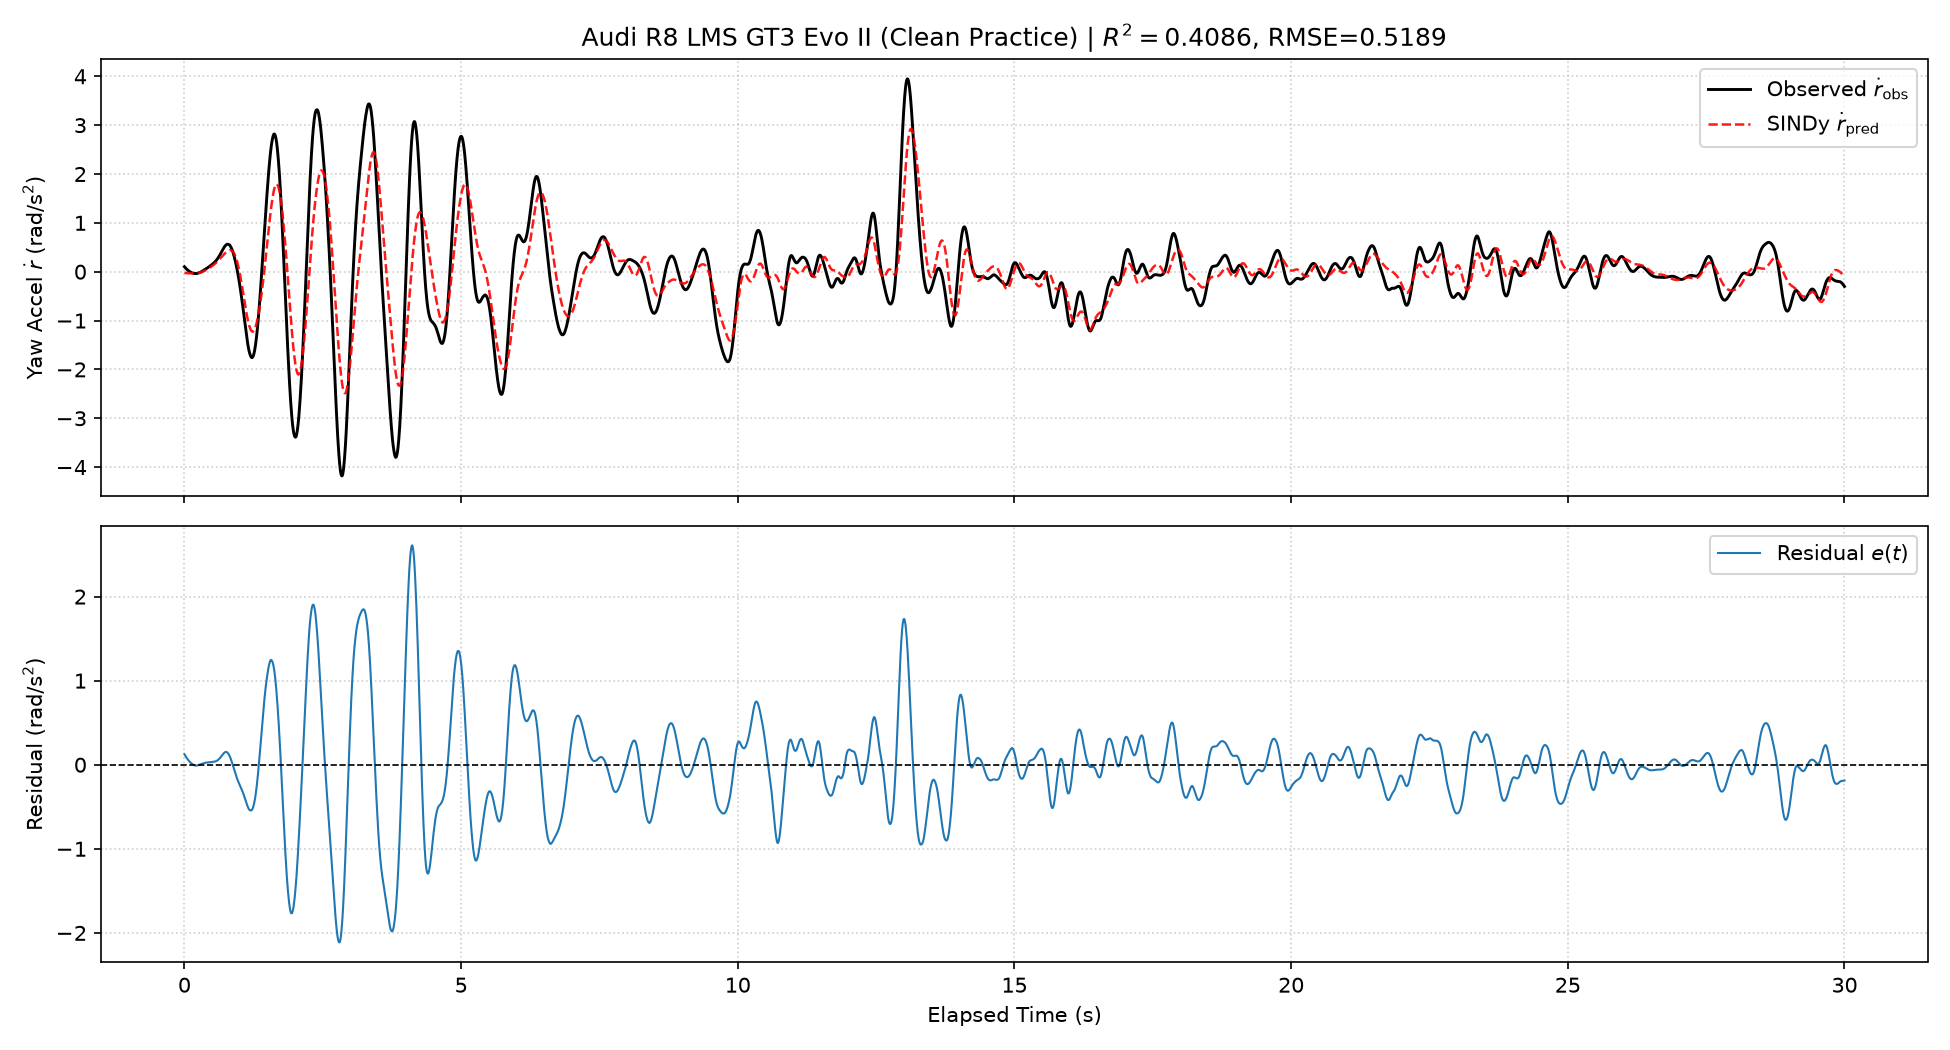

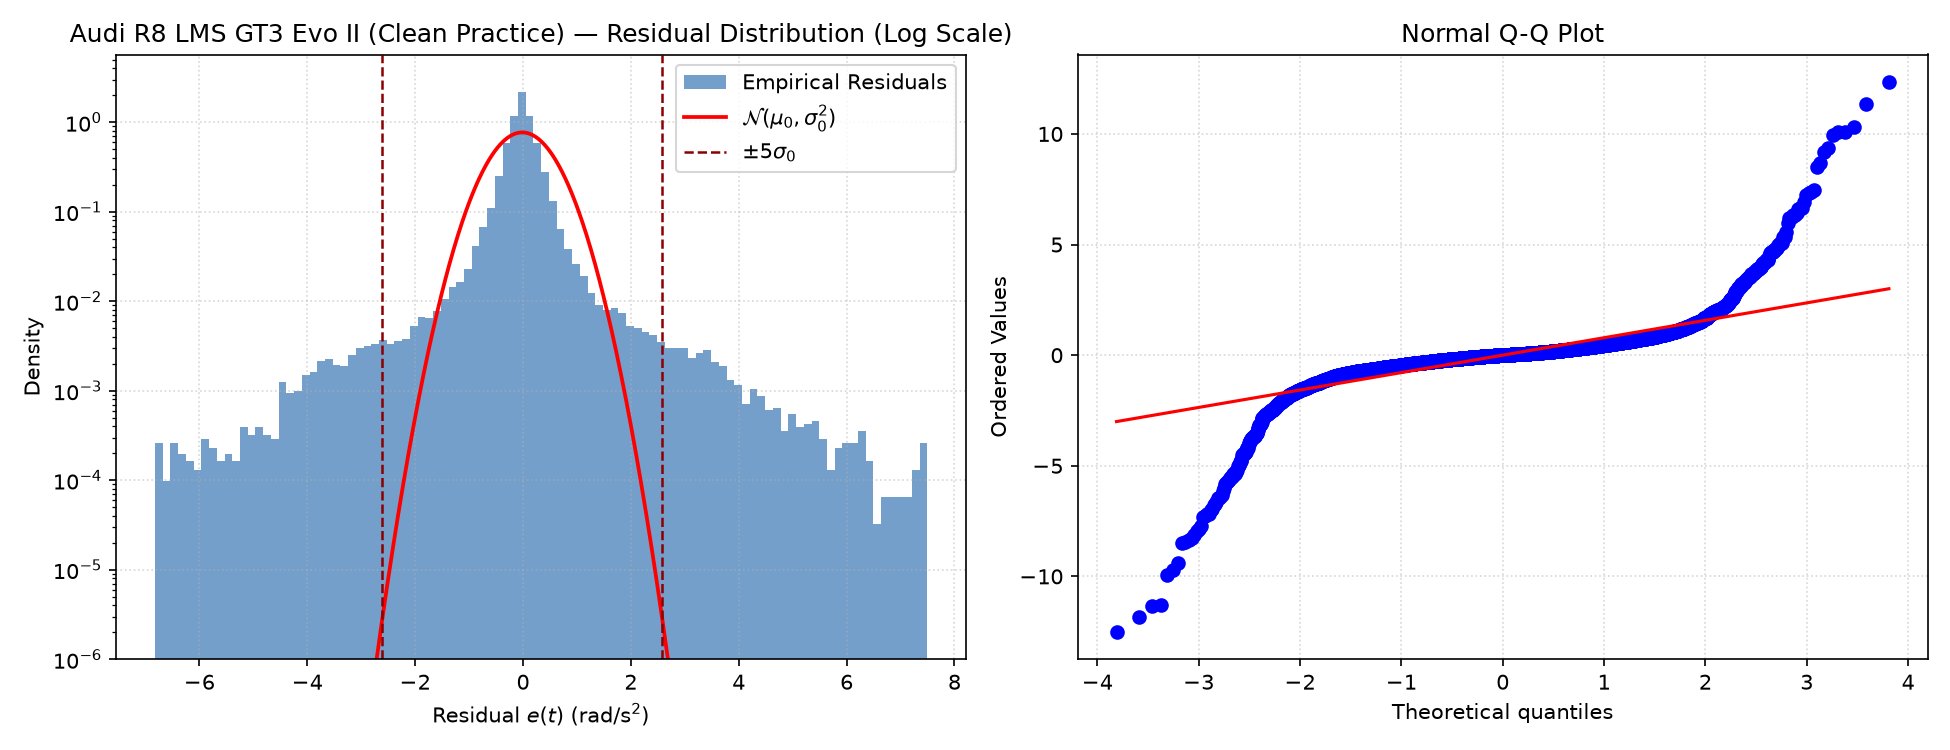

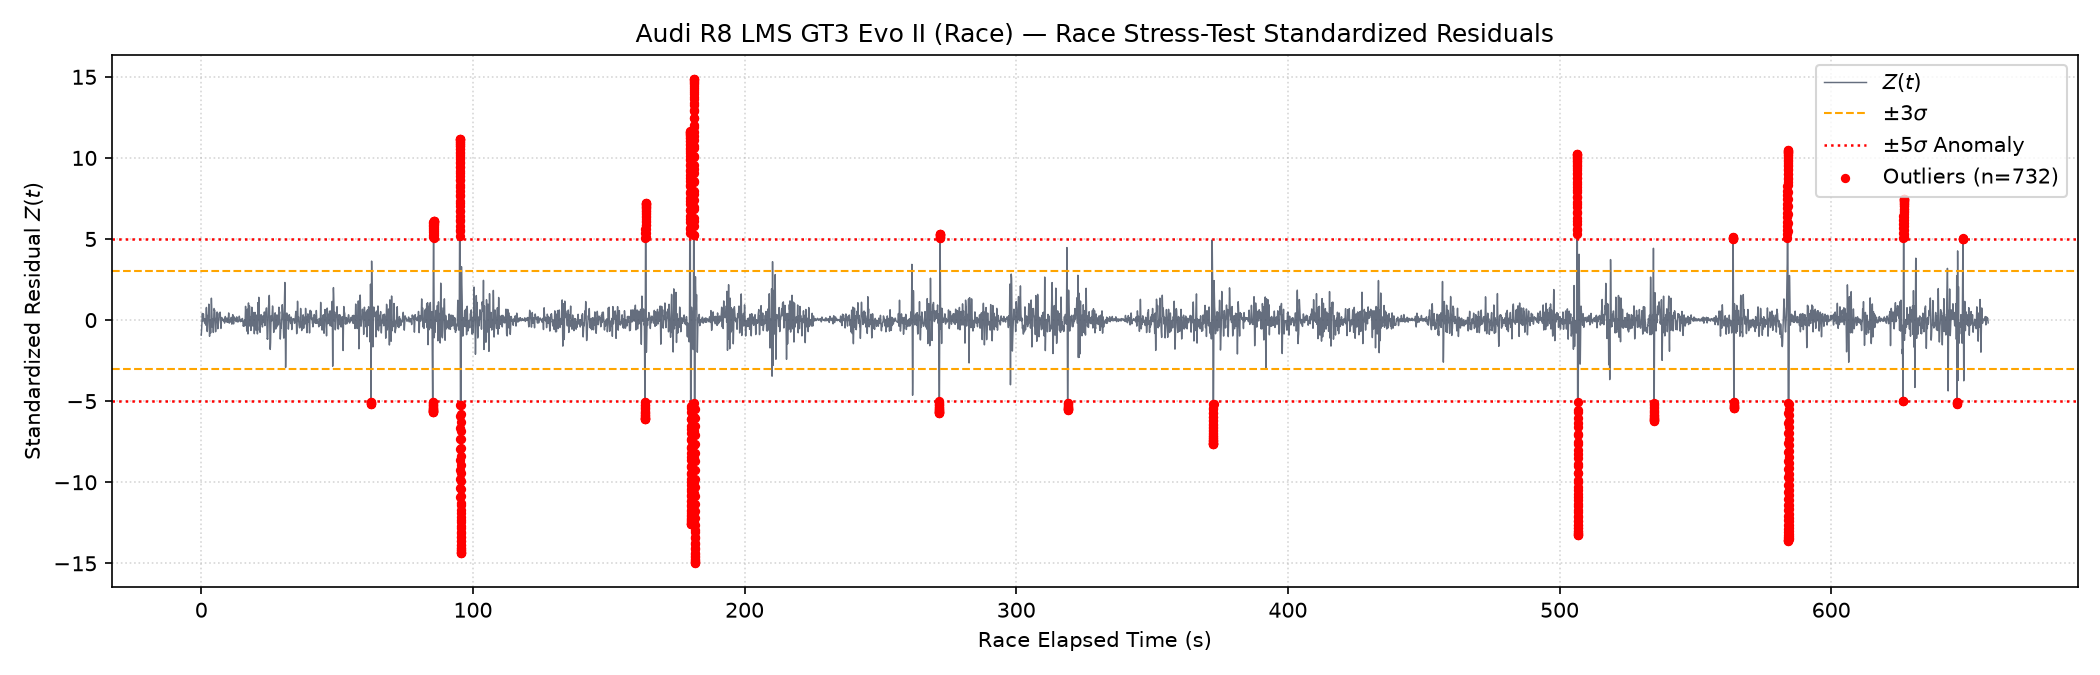

In [4]:
gt3_out = Path("outputs/stage2_barcelona_gt3_r8_A")
for img_name in ["clean_yaw_fit.png", "clean_residuals_qq.png", "race_anomaly_trace.png"]:
    display(Image(filename=str(gt3_out / img_name)))

## 2. Audi R8 LMS GT4 — Mechanical-Grip Baseline

In [5]:
gt4_report = run_pipeline("configs/experiments/stage2_planar_force/barcelona__audi_r8_gt4__a1.yaml")
print("Identified ODE:", gt4_report["equation"])
print(f"Clean Practice: R^2 = {gt4_report['clean_metrics']['r2']:.4f}, RMSE = {gt4_report['clean_metrics']['rmse']:.4f} rad/s^2")
print(f"Race Stress-Test: R^2 = {gt4_report['race_metrics']['r2']:.4f}, Within ±3σ = {gt4_report['race_metrics']['diagnostics']['within_3sigma_pct']:.2f}%")

INFO: Running experiment: r8_gt4_catalunya_planar (Audi R8 LMS GT4 @ Circuit de Barcelona-Catalunya)


INFO: Trimmed at SPEED >= 100.0 km/h (t=25.525s, 256828 -> 251723 rows)


INFO: Identified ODE: dr/dt = +0.30240 * r +0.07313 * a_y +0.28794 * a_y_dot +1.74401 * a_y_dot/v +0.02185 * a_y-v*r +0.03716 * a_y*|a_x| -0.00000 * a_y*(a_x^2+a_y^2)/eta_P^2 -0.15901 * r*|r|


INFO: Clean Practice R^2=0.5251 | RMSE=0.3208 rad/s^2


INFO: Substituting symbol N from STIXNonUnicode


INFO: Substituting symbol N from STIXNonUnicode


INFO: Trimmed at first_beacon t=65.664s (155093 -> 141960 rows)


INFO: Race Stress-Test R^2=0.4227 | Within ±3σ=97.68% | >5σ=1412


INFO: Artifacts saved to outputs/r8_gt4_catalunya_planar


Identified ODE: dr/dt = +0.30240 * r +0.07313 * a_y +0.28794 * a_y_dot +1.74401 * a_y_dot/v +0.02185 * a_y-v*r +0.03716 * a_y*|a_x| -0.00000 * a_y*(a_x^2+a_y^2)/eta_P^2 -0.15901 * r*|r|
Clean Practice: R^2 = 0.5251, RMSE = 0.3208 rad/s^2
Race Stress-Test: R^2 = 0.4227, Within ±3σ = 97.68%


In [6]:
display(Markdown("### GT4 Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)"))
display(pd.DataFrame(gt4_report["bootstrap"]["terms"]))

display(Markdown("### GT4 Type-I Error (Omission) Sweep — Clean Practice"))
display(pd.DataFrame(gt4_report["clean_metrics"]["diagnostics"]["omission_sweep"]))

display(Markdown("### GT4 Race >5σ Anomaly Corner Mapping"))
display(pd.Series(gt4_report["race_metrics"]["corner_anomalies"], name="Anomaly Frames").to_frame())

### GT4 Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)

,name,point_estimate,boot_mean,boot_std,ci_95_low,ci_95_high,t_statistic,p_value
0,r,3.023988e-01,3.170605e-01,3.008935e-01,-2.055695e-01,9.602780e-01,1.005003,0.315383
1,a_y,7.312546e-02,5.550767e-02,8.295403e-02,-9.444186e-02,2.230060e-01,0.881518,0.378462
2,a_y_dot,2.879357e-01,2.620879e-01,7.861890e-02,1.241909e-01,3.981150e-01,3.662424,0.000277
3,a_y_dot/v,1.744015e+00,2.458953e+00,2.293363e+00,-1.544502e+00,6.294533e+00,0.760462,0.447338
4,a_y-v*r,2.185465e-02,1.993100e-02,8.863382e-03,3.913581e-03,3.789313e-02,2.465724,0.014009
5,a_y*|a_x|,3.716027e-02,3.915117e-02,2.041333e-02,-3.310561e-03,7.624429e-02,1.820393,0.069298
6,a_y*(a_x^2+a_y^2)/eta_P^2,-1.127444e-07,-1.326077e-07,1.183778e-07,-4.496354e-07,-8.913787e-09,-0.952412,0.341349
7,r*|r|,-1.590103e-01,-1.872941e-01,2.917625e-01,-8.179746e-01,3.283486e-01,-0.544999,0.585998


### GT4 Type-I Error (Omission) Sweep — Clean Practice

,z_threshold,expected_omissions,actual_omissions,expected_pct,actual_pct
0,1.0,79874.352971,38086,31.731051,15.130123
1,2.0,11453.462929,10246,4.550026,4.070347
2,2.5,3126.231170,6495,1.241933,2.580217
3,3.0,679.600764,4529,0.269980,1.799200
4,3.5,117.116179,3291,0.046526,1.307389
5,4.0,15.944760,2406,0.006334,0.955813
6,5.0,0.144314,1410,0.000057,0.560140


### GT4 Race >5σ Anomaly Corner Mapping

,Anomaly Frames
T11-T14 Sector 3,684
T3 Renault,331
T7-T8 Chicane,190
T10 La Caixa,154
T5 Seat,53


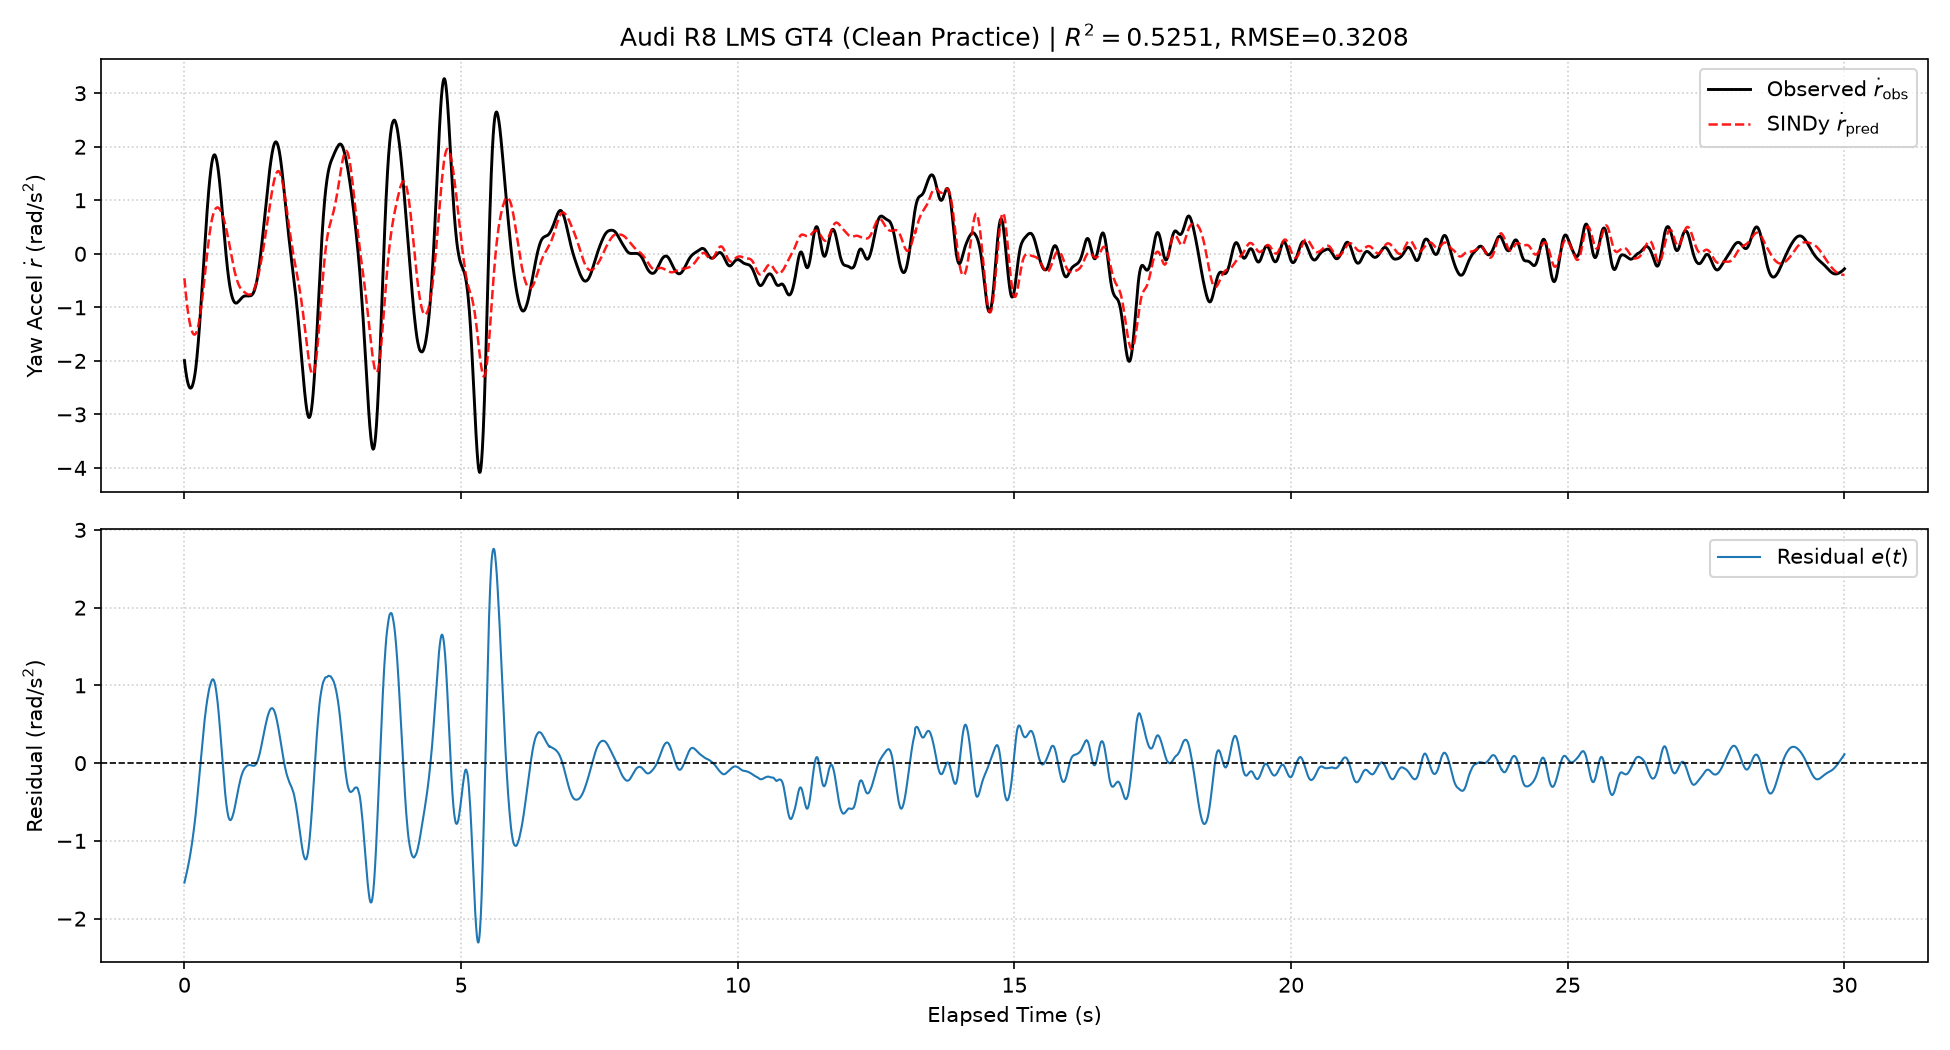

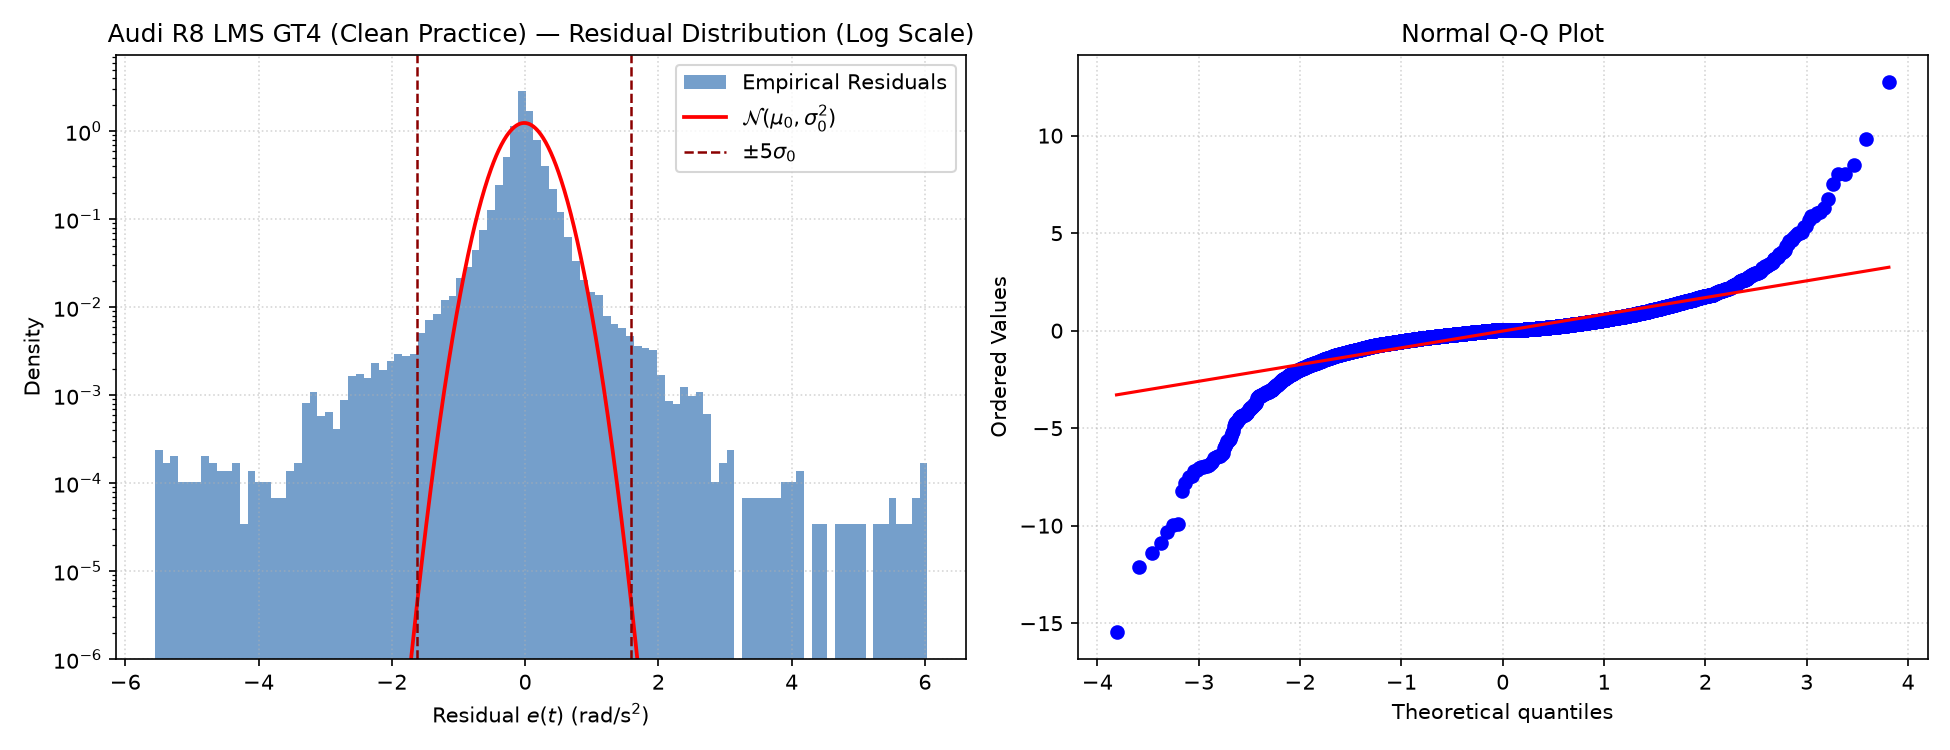

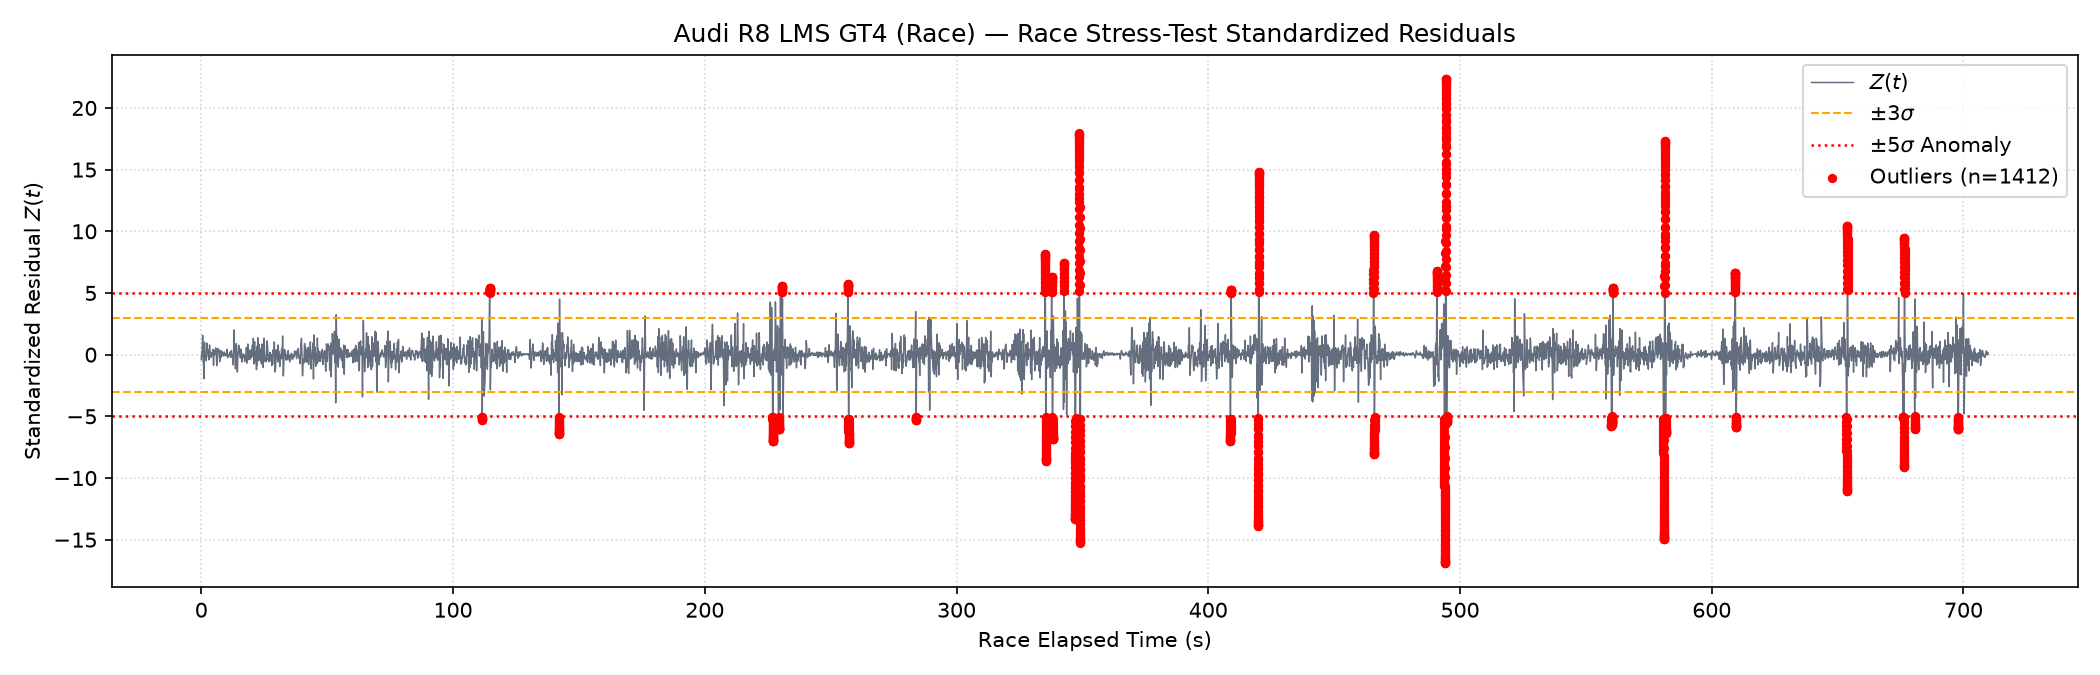

In [7]:
gt4_out = Path("outputs/stage2_barcelona_gt4_a1")
for img_name in ["clean_yaw_fit.png", "clean_residuals_qq.png", "race_anomaly_trace.png"]:
    display(Image(filename=str(gt4_out / img_name)))